# Tutorial 2 — An astrometric orbit: the planet Gaia-4 b

Tutorial 1 fitted a single star. This tutorial fits an orbit to the Gaia DR4
pre-release epoch astrometry of **Gaia-4**, the host of the planet Gaia-4 b
(Stefánsson et al. 2025, AJ 169, 107). The planet was found in Gaia DR3 astrometry
and confirmed with radial velocities.

**What you will do**

1. Fit the single-star model and see that it fails.
2. Write the orbit model: Kepler's equation, Thiele–Innes constants, along-scan projection.
3. Build the nine-column design matrix at a trial orbit shape.
4. Search the period with the $\chi^2$.
5. Refine the shape (P, e, τ) and solve the nine amplitudes.
6. List all parameters with their uncertainties and derive the planet mass.
7. Appendix: sample the shape with emcee.

**The source.** Gaia-4, `source_id` 1457486023639239296: G = 11.9 mag, parallax
13.6 mas (74 pc), 115 transits. Published orbit (Stefánsson et al. 2025):
P = 571.3 ± 1.4 d, photocentre semi-major axis a₀ = 0.312 ± 0.040 mas, planet mass
11.8 ± 0.7 M_J, host mass 0.644 ± 0.02 M☉. Eccentricity from HARPS-N radial
velocities (Pinamonti et al. 2026): e = 0.338 ± 0.025.

**Units and conventions**

- As in tutorial 1: mas, radians, TCB, reference epoch J2017.5 (`MJD_J2017_5_TCB`).
- Periods are in days at the orblet front door; design matrices take a frequency in
  cycles per day (`ti_design_matrix`) or a period in years (`rv_design_matrix`).
- The periastron time enters as the phase $\tau = (t_p - t_\mathrm{ref})/P \bmod 1$.
- Thiele–Innes constants $A, B, F, G$ in mas; $\Delta\alpha^* = BX + GY$,
  $\Delta\delta = AX + FY$.
- Data: ESA/Gaia/DPAC, see the
  [acknowledgement instructions](https://gea.esac.esa.int/archive/documentation/GDR3/Miscellaneous/sec_credit_and_citation_instructions/).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.optimize import minimize

from orblet.constants import MJD_J2010_TCB, MJD_J2017_5_TCB, DAYS_PER_KEPLER_YEAR, MSUN_IN_MJUP
from orblet import (resolve_epochs_mjd, fit_astrometric_5param, astrometric_5param_design_matrix,
                    ti_design_matrix, linear_solve_ti, scan_ti_frequency, ti_to_kepler)
from orblet.model import kepler_xy_orbit
from orblet.interpret.astrometric_upper_limit import a_phot_au, mass_function_au
from orblet.interpret.companion_mass import companion_mass_from_astrometric_posterior

# The loader and the markdown helpers of tutorial 1, now imported from the file next door.
from dr4_prerelease import (download_prerelease, read_prerelease, explode_transits,
                            matrix_markdown, params_markdown, source_id_of)

rng = np.random.default_rng(42)
EPOCH_REF = MJD_J2017_5_TCB

table = read_prerelease(download_prerelease("_data"))
SOURCE_ID = source_id_of("Gaia-4")
astro = explode_transits(table, SOURCE_ID)

t_mjd = resolve_epochs_mjd(astro)             # MJD (TCB)
t_yr = (t_mjd - EPOCH_REF) / DAYS_PER_KEPLER_YEAR
psi = astro["scan_angle"]
pf = astro["parallax_factor_al"]
w = astro["centroid_pos"]
sig = astro["centroid_pos_err"]
print(f"{astro['n_transits']} transits -> {w.size} CCD data over "
      f"{(t_mjd.max() - t_mjd.min()) / DAYS_PER_KEPLER_YEAR:.2f} yr; "
      f"median error {np.median(sig):.3f} mas; excess noise {astro['excess_noise_mas']:.3f} mas")

115 transits -> 824 CCD data over 4.94 yr; median error 0.082 mas; excess noise 0.119 mas


## 1. The single-star fit fails

Same fit as tutorial 1. Watch $\chi^2/\mathrm{dof}$.

**Single-star solution of Gaia-4**

| parameter | value | sigma | ESA gaiasupdate | diff / sigma |
|---|---:|---:|---:|---:|
| dra* (mas) | 0.0003 | 0.0036 | - | - |
| ddec (mas) | 0.0008 | 0.0047 | - | - |
| pmra* (mas/yr) | -75.5511 | 0.0027 | -75.5523 | 0.45 |
| pmdec (mas/yr) | 17.9404 | 0.0030 | 17.9440 | -1.20 |
| plx (mas) | 13.6215 | 0.0062 | 13.6241 | -0.42 |

chi2 / dof = 3.50   residual RMS = 0.154 mas   median sigma = 0.082 mas


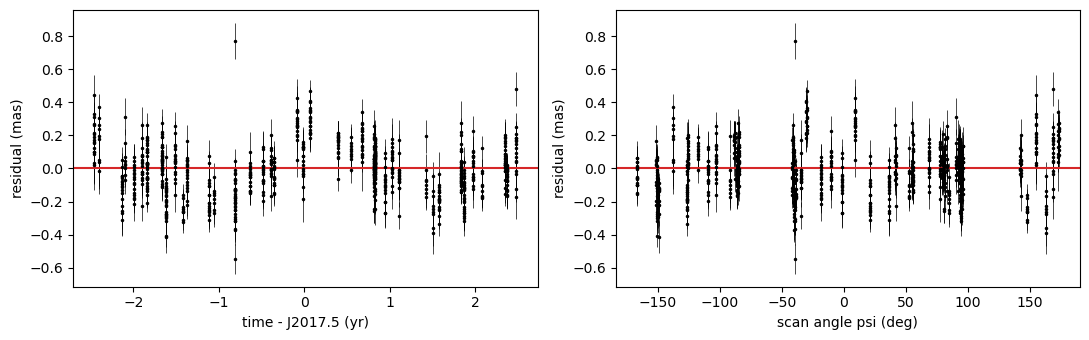

In [2]:
sol5 = fit_astrometric_5param(astro, epoch_ref_mjd=EPOCH_REF)
PARAMS5 = ["dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]
ESA5 = [None, None, -75.552329, 17.943998, 13.624072]     # gaiasupdate, ESA tutorial notebook
display(params_markdown(PARAMS5, sol5.params, np.sqrt(np.diag(sol5.cov)), reference=ESA5,
                        ref_label="ESA gaiasupdate", caption="Single-star solution of Gaia-4"))
print(f"chi2 / dof = {sol5.chi2_per_dof:.2f}   residual RMS = {sol5.rms_mas:.3f} mas   "
      f"median sigma = {np.median(sig):.3f} mas")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(t_yr, sol5.residuals, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[0].axhline(0, color="C3"); ax[0].set_xlabel("time - J2017.5 (yr)"); ax[0].set_ylabel("residual (mas)")
ax[1].errorbar(np.rad2deg(psi), sol5.residuals, yerr=sig, fmt=".", ms=3, color="k", lw=0.5)
ax[1].axhline(0, color="C3"); ax[1].set_xlabel("scan angle psi (deg)"); ax[1].set_ylabel("residual (mas)")
plt.tight_layout(); plt.show()

$\chi^2/\mathrm{dof} = 3.5$: the residuals are twice as large as the errors. The
single-star model misses something. The residuals show no clear pattern by eye: the
orbit is 0.3 mas in size and the data points are 0.1 mas each, under many scan
directions. The fit will find it; the eye cannot.

ESA's single-star values agree with ours, because the orbit averages out over the
data span. The excess noise of 0.12 mas is Gaia's way to say the same thing: the
single-star model does not fit.

## 2. The orbit model

The star moves around the barycentre of the star–planet system. The photocentre
(for a dark companion: the star) traces an ellipse on the sky. Its position at time
$t$ follows from Kepler's equation with the period $P$, the eccentricity $e$, and the
periastron time $t_p$:

$$
M = \frac{2\pi (t - t_p)}{P}, \qquad E - e\sin E = M, \qquad
X = \cos E - e, \qquad Y = \sqrt{1 - e^2}\,\sin E .
$$

$(X, Y)$ is the position in the orbit plane, in units of the semi-major axis. The
projection on the sky uses the four **Thiele–Innes constants**, which pack the
semi-major axis $a_0$ and the three angles $\omega$, $\Omega$, $i$:

$$
\begin{aligned}
A &= a_0 (\cos\omega \cos\Omega - \sin\omega \sin\Omega \cos i), &
B &= a_0 (\cos\omega \sin\Omega + \sin\omega \cos\Omega \cos i), \\
F &= a_0 (-\sin\omega \cos\Omega - \cos\omega \sin\Omega \cos i), &
G &= a_0 (-\sin\omega \sin\Omega + \cos\omega \cos\Omega \cos i),
\end{aligned}
\qquad
\Delta\alpha^*_\mathrm{orb} = B X + G Y, \quad \Delta\delta_\mathrm{orb} = A X + F Y .
$$

Gaia sees the along-scan projection, as in tutorial 1. The full model is the
single-star model plus the orbit term:

$$
w = \underbrace{\Delta\alpha^* \sin\psi + \Delta\delta \cos\psi
+ \mu_{\alpha*}\Delta t \sin\psi + \mu_\delta \Delta t \cos\psi + \varpi f_\mathrm{AL}}_{\text{single star}}
+ \underbrace{(BX + GY)\sin\psi + (AX + FY)\cos\psi}_{\text{orbit}} .
$$

Count the parameters. At a **fixed shape** $(P, e, t_p)$ the functions $X(t)$ and
$Y(t)$ are known numbers, and the model is **linear** in nine amplitudes:

$$
\boldsymbol\beta = (A, B, F, G, \Delta\alpha^*, \Delta\delta, \mu_{\alpha*}, \mu_\delta, \varpi)^\top,
\qquad
X_\mathrm{design} = \big[\,X\cos\psi,\; X\sin\psi,\; Y\cos\psi,\; Y\sin\psi,\;
\sin\psi,\; \cos\psi,\; \Delta t\sin\psi,\; \Delta t\cos\psi,\; f_\mathrm{AL}\,\big].
$$

Only three parameters are non-linear: $P$, $e$ and $t_p$. orblet writes $t_p$ as the
phase $\tau = (t_p - t_\mathrm{ref})/P \bmod 1$. So the plan is: search the three
shape parameters, and solve the nine amplitudes in closed form at every shape.

## 3. The nine-column design matrix at a trial shape

`ti_design_matrix` builds the matrix above. It takes the frequency $f = 1/P$ in
cycles per day. Take a trial shape near the published orbit and solve once.

In [3]:
P_trial, e_trial, tau_trial = 571.0, 0.3, 0.3
X9 = ti_design_matrix(t_mjd, psi, pf, f_per_day=1.0 / P_trial, ecc=e_trial, tau=tau_trial,
                      epoch_ref_mjd=EPOCH_REF)
COLS9 = ["X cos", "X sin", "Y cos", "Y sin", "sin", "cos", "dt sin", "dt cos", "f_AL"]
PARAMS9 = ["A (mas)", "B (mas)", "F (mas)", "G (mas)",
           "dra* (mas)", "ddec (mas)", "pmra* (mas/yr)", "pmdec (mas/yr)", "plx (mas)"]
display(matrix_markdown(X9, COLS9, n_rows=6, caption=f"Design matrix at P = {P_trial} d, e = {e_trial}, tau = {tau_trial}"))

sol9 = linear_solve_ti(w, sig, X9)
display(params_markdown(PARAMS9, sol9.beta, np.sqrt(np.diag(sol9.cov)),
                        caption="Nine amplitudes at the trial shape"))
print(f"chi2 / dof = {sol9.chi2 / sol9.dof:.3f}   logL_marginal = {sol9.logL_marginal:.1f}")

**Design matrix at P = 571.0 d, e = 0.3, tau = 0.3** (shape 824 x 9)

| row | X cos | X sin | Y cos | Y sin | sin | cos | dt sin | dt cos | f_AL |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 1 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 2 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 3 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 4 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 5 | 0.1535 | 0.6650 | 0.1982 | 0.8588 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| ... | ... | ... | ... | ... | ... | ... | ... | ... | ... |

**Nine amplitudes at the trial shape**

| parameter | value | sigma |
|---|---:|---:|
| A (mas) | -0.0798 | 0.0071 |
| B (mas) | -0.1171 | 0.0076 |
| F (mas) | -0.2318 | 0.0067 |
| G (mas) | 0.0591 | 0.0051 |
| dra* (mas) | -0.0885 | 0.0056 |
| ddec (mas) | -0.0096 | 0.0062 |
| pmra* (mas/yr) | -75.5326 | 0.0031 |
| pmdec (mas/yr) | 17.9633 | 0.0031 |
| plx (mas) | 13.6135 | 0.0063 |

chi2 / dof = 1.479   logL_marginal = 642.2


Columns 5–9 are the single-star columns of tutorial 1. Columns 1–4 are new: the orbit
coordinates $X$ and $Y$ at the time of each CCD, times $\cos\psi$ or $\sin\psi$. The
first six rows belong to one transit, so $X$, $Y$ and $\psi$ are the same and the
rows repeat.

One linear solve at this shape returns nine amplitudes, among them $A, B, F, G$ of
0.1–0.2 mas. The trial shape is not the best shape yet, but $\chi^2/\mathrm{dof}$
already dropped from 3.5 to 1.5.

## 4. Search the period with the $\chi^2$

To compare shapes you need one number per shape: the $\chi^2$ at the best amplitudes.
For Gaussian errors with $W = \mathrm{diag}(1/\sigma_i^2)$ it is

$$
\chi^2(P, e, \tau) = \left(\mathbf{d} - X\hat{\boldsymbol\beta}\right)^\top W
\left(\mathbf{d} - X\hat{\boldsymbol\beta}\right),
$$

with $\hat{\boldsymbol\beta}$ the best nine amplitudes at that shape. Smaller is better.
Two rules:

- Compare $\chi^2$ only between shapes of the **same** model (same data, same columns).
- `linear_solve_ti` returns it as `chi2`.

The solve also returns `logL_marginal`, the likelihood with the nine amplitudes
integrated out under a flat prior. With $M = X^\top W X$ it is
$-\tfrac{1}{2}\left[\chi^2 + \ln\det M\right] + \text{const}$. Do not choose a shape
with it: the $\ln\det M$ term rewards a shape whose amplitudes are poorly determined.
An eccentric orbit whose periastron passage holds no observation gains several units
from it against a worse $\chi^2$ (`docs/model_and_likelihoods.md` §2.4).

A **periodogram by hand**: loop over the period at $e = 0$ and plot the $\chi^2$. For a
circular orbit the phase $\tau$ does not matter: a shift of $\tau$ rotates $(X, Y)$,
and the amplitudes $A, B, F, G$ absorb a rotation.

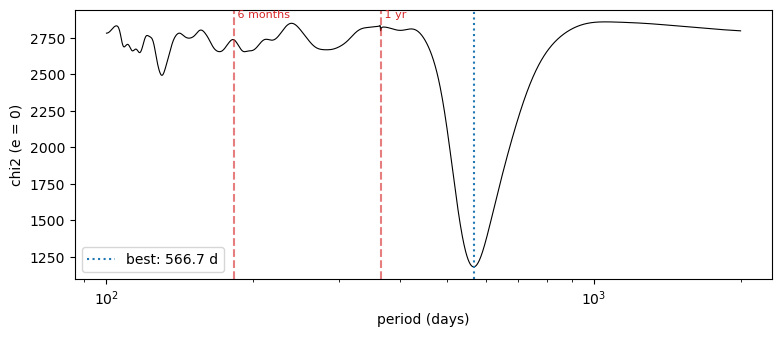

best circular period: 566.7 d  (published: 571.3 d)


In [4]:
periods = np.geomspace(100.0, 2000.0, 1500)
score = np.array([linear_solve_ti(w, sig, ti_design_matrix(
    t_mjd, psi, pf, f_per_day=1.0 / P, ecc=0.0, tau=0.0, epoch_ref_mjd=EPOCH_REF)).chi2
    for P in periods])
P_best_circ = periods[np.argmin(score)]   # the smallest chi2

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(periods, score, color="k", lw=0.8)
for P_alias, lab in [(365.25, "1 yr"), (365.25 / 2, "6 months")]:
    ax.axvline(P_alias, color="C3", ls="--", alpha=0.6)
    ax.text(P_alias, ax.get_ylim()[1], f" {lab}", color="C3", va="top", fontsize=8)
ax.axvline(P_best_circ, color="C0", ls=":", label=f"best: {P_best_circ:.1f} d")
ax.set_xscale("log"); ax.set_xlabel("period (days)"); ax.set_ylabel("chi2 (e = 0)")
ax.legend(); plt.show()
print(f"best circular period: {P_best_circ:.1f} d  (published: 571.3 d)")

One minimum near 570 days stands out: its $\chi^2$ is lower than elsewhere by
hundreds. The small side minima are **aliases**: Gaia revisits a source a few times per year, so a period
$P'$ with $1/P' = 1/P \pm 1/\mathrm{yr}$ can mimic the true one. Here they stay far
above the main minimum, because five years of data cover three orbits. The dashed
lines mark the 1-year and 6-month periods where the parallax and the orbit can mix.

## 5. Ranked search over (P, e, τ), then refine

`scan_ti_frequency` does the loop above on a grid in frequency, eccentricity and
phase. It returns the local minima of the $\chi^2$, smallest first (each one a
"peak"), and flags peaks at the yearly aliases. Then `scipy.optimize.minimize` (Nelder–Mead) refines the best
peak in the three shape parameters. Several starts in $(e, \tau)$ guard against a
local minimum.

In [5]:
peaks = scan_ti_frequency(
    t_mjd, psi, pf, w, sig,
    f_min_per_day=1.0 / 2000.0, f_max_per_day=1.0 / 100.0, oversample=4.0,
    ecc_grid=[0.0, 0.2, 0.4, 0.6], tau_grid=np.linspace(0.0, 1.0, 8, endpoint=False),
    epoch_ref_mjd=EPOCH_REF, top_k=5,
)
lines = ["| rank | P (d) | e | tau | chi2 | chi2 / dof | a_phot (mas) | alias flag |",
         "|---:|---:|---:|---:|---:|---:|---:|---|"]
for k, p in enumerate(peaks):
    a_mas = p.a_phot_au * p.plx_mas if p.a_phot_au is not None else np.nan
    lines.append(f"| {k} | {p.P_days:.1f} | {p.ecc:.1f} | {p.tau:.3f} | {p.chi2:.1f} "
                 f"| {p.chi2 / p.dof:.3f} | {a_mas:.3f} | {p.flagged} |")
display(Markdown("**Ranked peaks of the (P, e, tau) scan**\n\n" + "\n".join(lines)))


def solve_at(P, e, tau):
    # Closed-form nine amplitudes at one shape.
    X = ti_design_matrix(t_mjd, psi, pf, f_per_day=1.0 / P, ecc=e, tau=tau, epoch_ref_mjd=EPOCH_REF)
    return linear_solve_ti(w, sig, X), X


def chi2_at_shape(shape):
    P, e, tau = shape
    if not (100.0 < P < 2000.0 and 0.0 <= e < 0.95 and 0.0 <= tau < 1.0):
        return 1e12
    return solve_at(P, e, tau)[0].chi2


top = peaks[0]
best = None
for e0 in (0.1, 0.3, 0.5, 0.7):
    for tau0 in np.linspace(0.05, 0.95, 6):
        res = minimize(chi2_at_shape, [top.P_days, e0, tau0], method="Nelder-Mead",
                       options=dict(xatol=1e-4, fatol=1e-3))
        if best is None or res.fun < best.fun:
            best = res
P_ml, e_ml, tau_ml = best.x
print(f"refined shape: P = {P_ml:.2f} d, e = {e_ml:.3f}, tau = {tau_ml:.3f}   "
      f"(chi2 = {best.fun:.1f})")

**Ranked peaks of the (P, e, tau) scan**

| rank | P (d) | e | tau | chi2 | chi2 / dof | a_phot (mas) | alias flag |
|---:|---:|---:|---:|---:|---:|---:|---|
| 0 | 572.5 | 0.4 | 0.125 | 1145.3 | 1.405 | 0.258 | False |
| 1 | 129.8 | 0.6 | 0.375 | 2431.8 | 2.984 | 0.128 | False |
| 2 | 134.6 | 0.6 | 0.125 | 2441.7 | 2.996 | 0.130 | False |
| 3 | 117.2 | 0.6 | 0.375 | 2562.7 | 3.144 | 0.132 | False |
| 4 | 173.5 | 0.6 | 0.250 | 2565.8 | 3.148 | 0.128 | False |

refined shape: P = 578.96 d, e = 0.415, tau = 0.089   (chi2 = 1133.3)


## 6. Solve the nine amplitudes at the best shape

Now the design matrix is built at the refined shape, and one weighted least-squares
solve gives the amplitudes and their covariance.

In [6]:
sol_ml, X_ml = solve_at(P_ml, e_ml, tau_ml)
sigma_ml = np.sqrt(np.diag(sol_ml.cov))
display(matrix_markdown(X_ml, COLS9, n_rows=6, caption=f"Design matrix at P = {P_ml:.1f} d, e = {e_ml:.3f}, tau = {tau_ml:.3f}"))
display(params_markdown(PARAMS9, sol_ml.beta, sigma_ml, caption="Nine amplitudes at the best shape"))
print(f"chi2 / dof: single star {sol5.chi2_per_dof:.2f}  ->  with orbit {sol_ml.chi2 / sol_ml.dof:.3f}")

**Design matrix at P = 579.0 d, e = 0.415, tau = 0.089** (shape 824 x 9)

| row | X cos | X sin | Y cos | Y sin | sin | cos | dt sin | dt cos | f_AL |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 1 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 2 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 3 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 4 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| 5 | -0.1086 | -0.4704 | 0.0903 | 0.3911 | -0.9744 | -0.2249 | 1.4751 | 0.3404 | -0.6930 |
| ... | ... | ... | ... | ... | ... | ... | ... | ... | ... |

**Nine amplitudes at the best shape**

| parameter | value | sigma |
|---|---:|---:|
| A (mas) | 0.2046 | 0.0067 |
| B (mas) | -0.0926 | 0.0053 |
| F (mas) | -0.1509 | 0.0075 |
| G (mas) | -0.0951 | 0.0079 |
| dra* (mas) | -0.0856 | 0.0056 |
| ddec (mas) | 0.1457 | 0.0068 |
| pmra* (mas/yr) | -75.5323 | 0.0033 |
| pmdec (mas/yr) | 17.9656 | 0.0032 |
| plx (mas) | 13.6235 | 0.0063 |

chi2 / dof: single star 3.50  ->  with orbit 1.391


$\chi^2/\mathrm{dof}$ dropped from 3.5 to 1.4: the orbit model explains most of
the extra scatter. The rest is the per-transit noise that Gaia's excess-noise term
absorbs (the CCDs of one transit move together; look at the residual plot of
section 1). The five single-star parameters barely moved. The four Thiele–Innes
amplitudes are measured at 10–30 sigma each.

## 7. All parameters

The Thiele–Innes constants are not the quantities you want to read. `ti_to_kepler`
inverts them to the Campbell elements $a_0$, $i$, $\omega$, $\Omega$:

$$
u = \tfrac{1}{2}(A^2 + B^2 + F^2 + G^2), \quad v = AG - BF, \quad
a_0 = \sqrt{u + \sqrt{(u + v)(u - v)}},
$$
$$
\omega + \Omega = \operatorname{atan2}(B - F,\, A + G), \quad
\omega - \Omega = \operatorname{atan2}(-(B + F),\, A - G), \quad
\tan^4\!\tfrac{i}{2} = \frac{(A - G)^2 + (B + F)^2}{(A + G)^2 + (B - F)^2}.
$$

To carry the uncertainties through this non-linear map, draw amplitude vectors from
the Gaussian $\mathcal{N}(\hat{\boldsymbol\beta}, \mathrm{Cov})$ and convert every
draw. The table lists the 16, 50 and 84 % quantiles.

Two cautions. (1) These uncertainties are **conditional** on the shape $(P, e, \tau)$
at its best value; the appendix adds the shape uncertainty. (2) Along-scan astrometry
alone does not tell which node is ascending: $(\omega, \Omega)$ and
$(\omega + 180°, \Omega + 180°)$ give the same $A, B, F, G$. Radial velocities break
this tie.

In [7]:
N_DRAW = 4000
betas = rng.multivariate_normal(sol_ml.beta, sol_ml.cov, size=N_DRAW)
kep = ti_to_kepler({"A_mas": betas[:, 0], "B_mas": betas[:, 1], "F_mas": betas[:, 2],
                    "G_mas": betas[:, 3], "plx_mas": betas[:, 8]})
tp_ml = tau_ml * P_ml + EPOCH_REF            # periastron time from the phase

# Published values: Stefansson et al. 2025 (P, a0), Pinamonti et al. 2026 (e); ESA 5p for the rest.
REFERENCE = {"P (d)": 571.3, "e": 0.338, "a0 (mas)": 0.312,
             "pmra* (mas/yr)": -75.552329, "pmdec (mas/yr)": 17.943998, "plx (mas)": 13.624072}


def quantile_table(rows, caption):
    # rows: list of (name, draws or scalar). Scalars are the fixed shape parameters.
    lines = ["| parameter | 16 % | 50 % | 84 % | published |", "|---|---:|---:|---:|---:|"]
    for name, arr in rows:
        ref = REFERENCE.get(name)
        ref_s = "" if ref is None else f"{ref:.4f}"
        if np.ndim(arr) == 0:
            lines.append(f"| {name} | | {arr:.4f} (fixed) | | {ref_s} |")
        else:
            q = np.percentile(arr, [16, 50, 84])
            lines.append(f"| {name} | {q[0]:.4f} | {q[1]:.4f} | {q[2]:.4f} | {ref_s} |")
    return Markdown(f"**{caption}**\n\n" + "\n".join(lines))


rows = [("P (d)", P_ml), ("e", e_ml), ("tau", tau_ml), ("tp (MJD)", tp_ml),
        ("A (mas)", betas[:, 0]), ("B (mas)", betas[:, 1]), ("F (mas)", betas[:, 2]), ("G (mas)", betas[:, 3]),
        ("a0 (mas)", kep["a_phot_mas"]), ("i (deg)", np.rad2deg(kep["inc_rad"])),
        ("omega (deg)", np.rad2deg(kep["omega_rad"]) % 360), ("Omega (deg)", np.rad2deg(kep["Omega_rad"]) % 360),
        ("dra* (mas)", betas[:, 4]), ("ddec (mas)", betas[:, 5]),
        ("pmra* (mas/yr)", betas[:, 6]), ("pmdec (mas/yr)", betas[:, 7]), ("plx (mas)", betas[:, 8])]
display(quantile_table(rows, "Orbit of Gaia-4 b: shape fixed at the best value, amplitudes drawn from their covariance"))

**Orbit of Gaia-4 b: shape fixed at the best value, amplitudes drawn from their covariance**

| parameter | 16 % | 50 % | 84 % | published |
|---|---:|---:|---:|---:|
| P (d) | | 578.9575 (fixed) | | 571.3000 |
| e | | 0.4147 (fixed) | | 0.3380 |
| tau | | 0.0885 (fixed) | |  |
| tp (MJD) | | 57987.6409 (fixed) | |  |
| A (mas) | 0.1979 | 0.2046 | 0.2113 |  |
| B (mas) | -0.0981 | -0.0926 | -0.0874 |  |
| F (mas) | -0.1581 | -0.1507 | -0.1432 |  |
| G (mas) | -0.1028 | -0.0948 | -0.0869 |  |
| a0 (mas) | 0.2484 | 0.2553 | 0.2621 | 0.3120 |
| i (deg) | 118.7257 | 120.8015 | 123.0415 |  |
| omega (deg) | 31.1045 | 33.5179 | 35.9874 |  |
| Omega (deg) | 352.2697 | 354.3669 | 356.4771 |  |
| dra* (mas) | -0.0911 | -0.0856 | -0.0799 |  |
| ddec (mas) | 0.1385 | 0.1456 | 0.1525 |  |
| pmra* (mas/yr) | -75.5355 | -75.5323 | -75.5291 | -75.5523 |
| pmdec (mas/yr) | 17.9625 | 17.9657 | 17.9688 | 17.9440 |
| plx (mas) | 13.6173 | 13.6237 | 13.6299 | 13.6241 |

## 8. The planet mass

Astrometry gives the size of the star's orbit around the barycentre, $a_0$ in mas.
With the parallax it becomes au, and with the period it gives the **astrometric mass
function**:

$$
f_\mathrm{ast} = \frac{a_0^3\,[\mathrm{au}]}{P^2\,[\mathrm{yr}]} = \frac{m_2^3}{(m_1 + m_2)^2}
\qquad [M_\odot],
$$

valid for a dark companion (all light from the star). Unlike the spectroscopic mass
function, there is no $\sin i$: the inclination is already in $a_0$. To get $m_2$
you need $m_1$ from outside (a stellar model). orblet solves the cubic for every
draw, with $m_1$ drawn from the stated prior.

In [8]:
a0_au = a_phot_au(kep["a_phot_mas"], betas[:, 8])          # mas / mas -> au
fm_ast = mass_function_au(a0_au, P_ml)                     # M_sun
mass = companion_mass_from_astrometric_posterior(
    {"chains": {"fm_ast_msun": fm_ast, "A_mas": betas[:, 0], "B_mas": betas[:, 1],
                "F_mas": betas[:, 2], "G_mas": betas[:, 3]}},
    primary_mass_prior=("Normal", 0.644, 0.02), seed=0)
m2_mjup = mass["mass"]["m2"] * MSUN_IN_MJUP
q = np.nanpercentile(m2_mjup, [16, 50, 84])
print(f"a0 = {np.median(a0_au):.4f} au, f_ast = {np.median(fm_ast):.2e} M_sun")
print(f"planet mass m2 = {q[1]:.1f} (+{q[2] - q[1]:.1f} / -{q[1] - q[0]:.1f}) M_J   "
      f"(published 11.8 +/- 0.7 M_J; m1 = 0.644 +/- 0.02 M_sun assumed)")

a0 = 0.0187 au, f_ast = 2.62e-06 M_sun
planet mass m2 = 10.9 (+0.4 / -0.4) M_J   (published 11.8 +/- 0.7 M_J; m1 = 0.644 +/- 0.02 M_sun assumed)


## Appendix: sample the shape with emcee

Section 7 held $(P, e, \tau)$ fixed. To include their uncertainty, sample the three
shape parameters with the marginal likelihood as the target (the nine amplitudes stay
integrated out), with a flat prior inside a box. Section 5 chose the best shape by the
$\chi^2$; for a well-measured orbit like this one the two agree near the minimum. Then draw amplitudes at every sample
as before. This needs the `sampling` extra (`emcee`) and the `plots` extra (`corner`).

mean acceptance fraction: 0.65


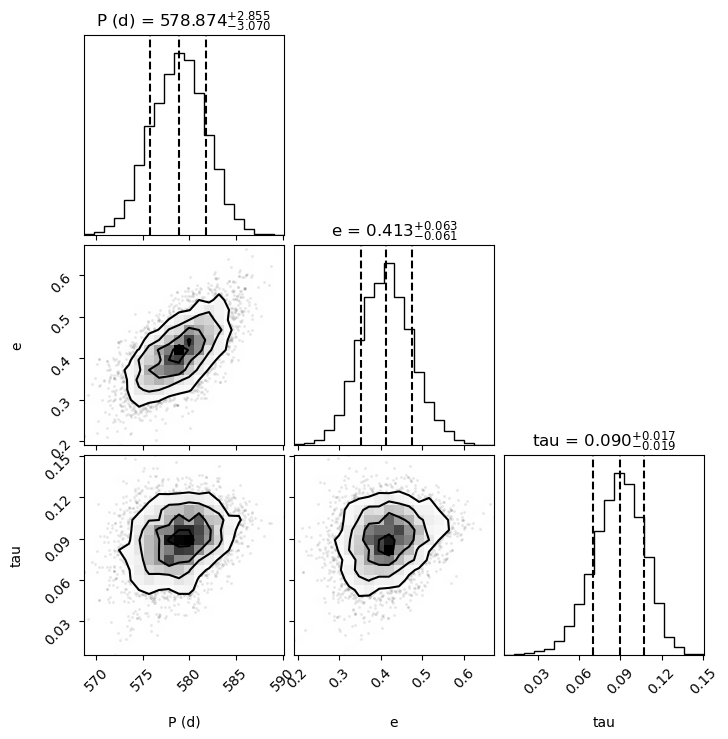

In [9]:
import emcee
import corner

P_LO, P_HI = 500.0, 650.0


def log_prob(theta):
    P, e, tau = theta
    if not (P_LO < P < P_HI and 0.0 <= e < 0.95 and 0.0 <= tau < 1.0):
        return -np.inf
    return float(solve_at(P, e, tau)[0].logL_marginal)


n_walkers, n_dim, n_steps = 24, 3, 1500
p0 = np.array([P_ml, e_ml, tau_ml]) + 1e-3 * rng.standard_normal((n_walkers, n_dim))
p0[:, 1] = np.clip(p0[:, 1], 0.0, 0.94); p0[:, 2] = p0[:, 2] % 1.0
sampler = emcee.EnsembleSampler(n_walkers, n_dim, log_prob)
sampler.random_state = np.random.RandomState(1).get_state()
sampler.run_mcmc(p0, n_steps, progress=False)
print(f"mean acceptance fraction: {np.mean(sampler.acceptance_fraction):.2f}")

flat = sampler.get_chain(discard=500, thin=5, flat=True)
fig = corner.corner(flat, labels=["P (d)", "e", "tau"], show_titles=True, title_fmt=".3f",
                    quantiles=[0.16, 0.5, 0.84])
plt.show()

In [10]:
# One amplitude draw per shape sample -> all parameters with the shape uncertainty included.
betas_mc = np.empty((len(flat), 9))
for k, (P, e, tau) in enumerate(flat):
    s = solve_at(P, e, tau)[0]
    betas_mc[k] = rng.multivariate_normal(s.beta, s.cov)
kep_mc = ti_to_kepler({"A_mas": betas_mc[:, 0], "B_mas": betas_mc[:, 1], "F_mas": betas_mc[:, 2],
                       "G_mas": betas_mc[:, 3], "plx_mas": betas_mc[:, 8]})
tp_mc = flat[:, 2] * flat[:, 0] + EPOCH_REF
fm_mc = mass_function_au(a_phot_au(kep_mc["a_phot_mas"], betas_mc[:, 8]), flat[:, 0])
m2_mc = companion_mass_from_astrometric_posterior(
    {"chains": {"fm_ast_msun": fm_mc, "A_mas": betas_mc[:, 0], "B_mas": betas_mc[:, 1],
                "F_mas": betas_mc[:, 2], "G_mas": betas_mc[:, 3]}},
    primary_mass_prior=("Normal", 0.644, 0.02), seed=1)["mass"]["m2"] * MSUN_IN_MJUP

rows = [("P (d)", flat[:, 0]), ("e", flat[:, 1]), ("tau", flat[:, 2]), ("tp (MJD)", tp_mc),
        ("A (mas)", betas_mc[:, 0]), ("B (mas)", betas_mc[:, 1]), ("F (mas)", betas_mc[:, 2]), ("G (mas)", betas_mc[:, 3]),
        ("a0 (mas)", kep_mc["a_phot_mas"]), ("i (deg)", np.rad2deg(kep_mc["inc_rad"])),
        ("omega (deg)", np.rad2deg(kep_mc["omega_rad"]) % 360), ("Omega (deg)", np.rad2deg(kep_mc["Omega_rad"]) % 360),
        ("dra* (mas)", betas_mc[:, 4]), ("ddec (mas)", betas_mc[:, 5]),
        ("pmra* (mas/yr)", betas_mc[:, 6]), ("pmdec (mas/yr)", betas_mc[:, 7]), ("plx (mas)", betas_mc[:, 8]),
        ("m2 (M_J)", m2_mc[np.isfinite(m2_mc)])]
REFERENCE["m2 (M_J)"] = 11.8
display(quantile_table(rows, "Orbit of Gaia-4 b: full posterior (shape sampled, amplitudes drawn)"))

**Orbit of Gaia-4 b: full posterior (shape sampled, amplitudes drawn)**

| parameter | 16 % | 50 % | 84 % | published |
|---|---:|---:|---:|---:|
| P (d) | 575.8046 | 578.8745 | 581.7296 | 571.3000 |
| e | 0.3521 | 0.4130 | 0.4758 | 0.3380 |
| tau | 0.0705 | 0.0896 | 0.1069 |  |
| tp (MJD) | 57977.1184 | 57988.2578 | 57998.3962 |  |
| A (mas) | 0.1866 | 0.2045 | 0.2208 |  |
| B (mas) | -0.1035 | -0.0930 | -0.0811 |  |
| F (mas) | -0.1786 | -0.1526 | -0.1232 |  |
| G (mas) | -0.1074 | -0.0949 | -0.0823 |  |
| a0 (mas) | 0.2473 | 0.2555 | 0.2650 | 0.3120 |
| i (deg) | 118.6852 | 120.8153 | 122.9942 |  |
| omega (deg) | 25.9356 | 33.9698 | 41.3191 |  |
| Omega (deg) | 352.1443 | 354.4040 | 356.6149 |  |
| dra* (mas) | -0.0986 | -0.0851 | -0.0724 |  |
| ddec (mas) | 0.1240 | 0.1443 | 0.1664 |  |
| pmra* (mas/yr) | -75.5356 | -75.5324 | -75.5291 | -75.5523 |
| pmdec (mas/yr) | 17.9625 | 17.9656 | 17.9687 | 17.9440 |
| plx (mas) | 13.6171 | 13.6234 | 13.6299 | 13.6241 |
| m2 (M_J) | 10.4858 | 10.9021 | 11.3611 | 11.8000 |

Now $P$, $e$ and $\tau$ carry uncertainties, and they widen $a_0$ and the mass. The
period is 7 days (2 sigma) longer than the radial-velocity period of Stefánsson et
al., and $e$ is 1.3 sigma higher; the planet mass agrees within 1 sigma. Two
reasons for the tension: the formal errors treat the CCDs of a transit as
independent, which they are not ($\chi^2/\mathrm{dof} = 1.4$), and the published
values combine radial velocities with the DR3 astrometry. Tutorial 3 shows what
radial velocities add.

## 9. The path on the sky

Gaia measures one coordinate per CCD. To draw the path of the star on the sky, the
model supplies the other coordinate: each transit mean sits at the model position,
moved by its residual along the scan direction. The two sky components of the
parallax come from `per_direction_parallax_factors` (Gaia at L2; they agree with the
file's along-scan factor to 0.1 %). The plot uses the maximum-likelihood solution
of section 6. The colour is time.

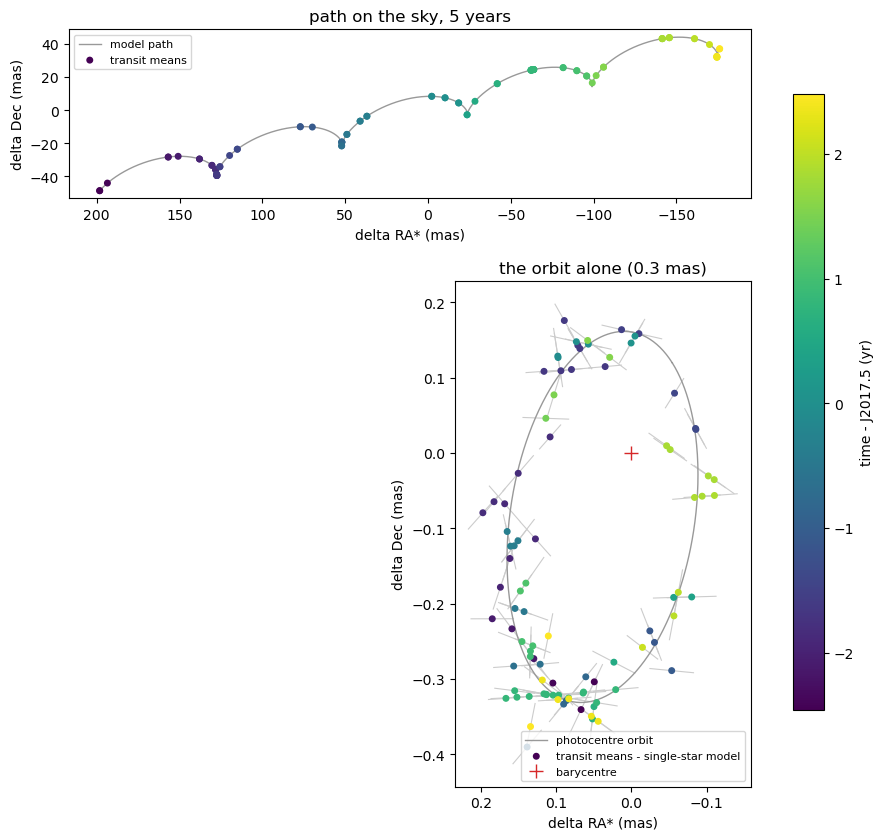

In [11]:
from orblet.parallax import per_direction_parallax_factors

beta = sol_ml.beta
P_yr = P_ml / DAYS_PER_KEPLER_YEAR


def sky_model(t, beta, orbit=True):
    # 2-D offsets (dRA*, dDec) in mas from (ra0, dec0): position + proper motion + parallax (+ orbit).
    dt = (t - EPOCH_REF) / DAYS_PER_KEPLER_YEAR
    F_ra, F_dec = per_direction_parallax_factors(t, astro["ra0_deg"], astro["dec0_deg"])
    ra = beta[4] + beta[6] * dt + beta[8] * F_ra
    dec = beta[5] + beta[7] * dt + beta[8] * F_dec
    if orbit:
        x, y = kepler_xy_orbit(t, period_yr=P_yr, ecc=e_ml, tp_mjd=tp_ml)
        ra, dec = ra + beta[1] * x + beta[3] * y, dec + beta[0] * x + beta[2] * y
    return ra, dec


# Data on the sky: model position + residual along the scan direction, averaged per transit.
resid = w - X_ml @ beta
ra_m, dec_m = sky_model(t_mjd, beta)
ra_s, dec_s = sky_model(t_mjd, beta, orbit=False)          # single-star part, to isolate the orbit
uniq, inv = np.unique(astro["transit_id"], return_inverse=True)
n_per = np.bincount(inv)
ra_tr, dec_tr, t_tr, psi_tr = (np.bincount(inv, a) / n_per for a in
                               (ra_m + resid * np.sin(psi), dec_m + resid * np.cos(psi), t_yr, psi))
ra_orb, dec_orb = (np.bincount(inv, a) / n_per for a in (ra_m - ra_s + resid * np.sin(psi), dec_m - dec_s + resid * np.cos(psi)))
sig_tr = np.sqrt(np.bincount(inv, sig ** 2)) / n_per

t_curve = np.linspace(t_mjd.min(), t_mjd.max(), 3000)
ra_c, dec_c = sky_model(t_curve, beta)
t_orb = tp_ml + np.linspace(0.0, P_ml, 500)
xo, yo = kepler_xy_orbit(t_orb, period_yr=P_yr, ecc=e_ml, tp_mjd=tp_ml)

# The path is wide and flat, the orbit is round: give them one row each.
fig = plt.figure(figsize=(11, 10))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 2.6])
ax = [fig.add_subplot(gs[0]), fig.add_subplot(gs[1])]
ax[0].plot(ra_c, dec_c, color="0.6", lw=1, label="model path")
sc = ax[0].scatter(ra_tr, dec_tr, c=t_tr, cmap="viridis", s=16, zorder=3, label="transit means")
ax[0].set_title("path on the sky, 5 years")
ax[1].plot(beta[1] * xo + beta[3] * yo, beta[0] * xo + beta[2] * yo, color="0.6", lw=1, label="photocentre orbit")
for r, d, s, p in zip(ra_orb, dec_orb, sig_tr, psi_tr):     # +/- 1 sigma along the scan direction
    ax[1].plot([r - s * np.sin(p), r + s * np.sin(p)], [d - s * np.cos(p), d + s * np.cos(p)], color="0.8", lw=0.8, zorder=1)
ax[1].scatter(ra_orb, dec_orb, c=t_tr, cmap="viridis", s=16, zorder=3, label="transit means - single-star model")
ax[1].plot(0, 0, "+", color="C3", ms=10, label="barycentre")
ax[1].set_title("the orbit alone (0.3 mas)")
for a in ax:
    a.set_xlabel("delta RA* (mas)"); a.set_ylabel("delta Dec (mas)"); a.invert_xaxis(); a.set_aspect("equal"); a.legend(fontsize=8)
fig.colorbar(sc, ax=ax, label="time - J2017.5 (yr)", shrink=0.8); plt.show()

Left: the star moves 390 mas in five years; the parallax (14 mas) is the wiggle; the
orbit (0.3 mas) is invisible at this scale. Right: the same data with the
single-star model removed. Each transit mean carries a bar of ±1 sigma along its
scan direction; across the scan it sits on the model by construction. Every
transit measures one coordinate, and the orbit emerges from many transits under
many angles.

## Summary

- An orbit adds four linear amplitudes (the Thiele–Innes constants) and three
  non-linear shape parameters to the single-star model.
- At a fixed shape the fit is one linear solve. The $\chi^2$ at the best amplitudes
  ranks the shapes. A scan over the period finds the orbit; aliases at ±1 cycle per year are
  the usual traps.
- `ti_to_kepler` turns the amplitudes into $a_0$, $i$, $\omega$, $\Omega$; the mass
  function and an external $m_1$ give the companion mass.

**Exercises**

1. Rerun with `SOURCE_ID = source_id_of("HD 114762")`: a bright star (G = 7) with a
   brown-dwarf companion on a 84-day orbit. Widen the period range of the scan.
2. Fix the period at the 1-year alias of the peak and compare $\chi^2/\mathrm{dof}$.
3. Fit with the excess noise added to the errors (`add_excess_noise=True`). What
   changes in the formal errors?